### **Anomaly Detection is the process of identifying data points that behave differently from most of the data.**

### **Algorithm 1: Isolation Forest**
##### Isolation Forest identifies unusual observations by isolating them through random feature-based splits.
##### The intuition is that unusual observations can often be isolated with fewer splits than typical observations.

### **Algorithm 2: Local Outlier Factor (LOF)**

##### LOF compares the local density around a sample with the density around its neighbors.

##### A sample may be considered anomalous if its local density is substantially lower than that of its neighbors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA

In [2]:
data = load_wine(as_frame=True)

X = data.data

print("Dataset shape:", X.shape)

X.head()

Dataset shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (178, 13)
Scaled shape: (178, 13)


#### **Isolation Forest tries to separate individual samples by repeatedly splitting the data using randomly selected features and split values.**

In [4]:
isolation_model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

isolation_model.fit(X_scaled)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


| Prediction | Meaning       |
| ---------: | ------------- |
|        `1` | Normal sample |
|       `-1` | Anomaly       |


In [5]:
predictions = isolation_model.predict(X_scaled)

print(predictions[:20])

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [6]:
anomaly_count = np.sum(predictions == -1)

normal_count = np.sum(predictions == 1)

print("Normal samples:", normal_count)
print("Anomalies:", anomaly_count)

Normal samples: 169
Anomalies: 9


In [ ]:
results = X.copy()

results["Prediction"] = predictions

results["Status"] = np.where(
    predictions == -1,
    "Anomaly",
    "Normal"
)


results.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Prediction,Status
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1,Normal
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1,Normal
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1,Normal
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1,Normal
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1,Normal
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,1,Normal
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,1,Normal
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,1,Normal
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,1,Normal
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,1,Normal


In [8]:
anomaly_scores = isolation_model.decision_function(X_scaled)

print(anomaly_scores[:10])

[0.07779505 0.07675937 0.08474631 0.00846042 0.10825512 0.09219797
 0.08342977 0.06950884 0.09190839 0.08838377]


In [9]:
results["Anomaly_Score"] = anomaly_scores

results.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Prediction,Status,Anomaly_Score
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1,Normal,0.077795
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1,Normal,0.076759
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1,Normal,0.084746
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1,Normal,0.008460
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1,Normal,0.108255
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,1,Normal,0.092198
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,1,Normal,0.083430
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,1,Normal,0.069509
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,1,Normal,0.091908
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,1,Normal,0.088384


In [10]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (178, 13)
PCA shape: (178, 2)


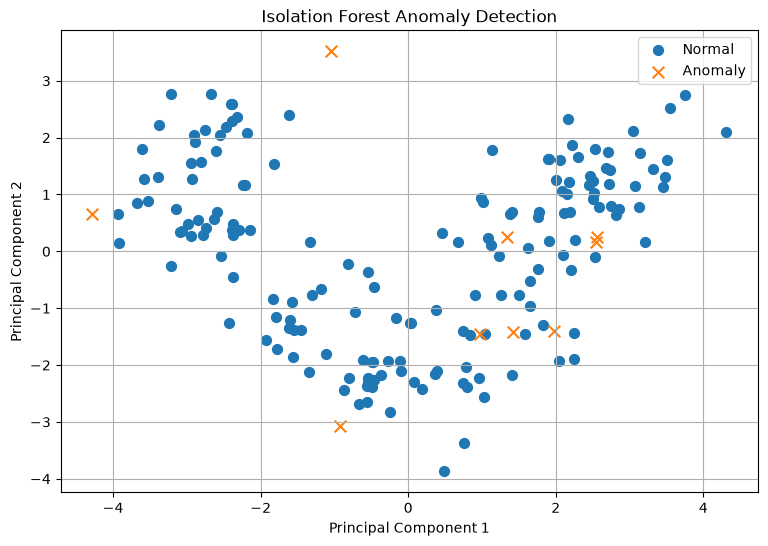

In [11]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[predictions == 1, 0],
    X_pca[predictions == 1, 1],
    label="Normal",
    s=50
)

plt.scatter(
    X_pca[predictions == -1, 0],
    X_pca[predictions == -1, 1],
    label="Anomaly",
    s=70,
    marker="x"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Isolation Forest Anomaly Detection")

plt.legend()
plt.grid(True)

plt.show()

### **LOF identifies samples whose local density is unusually low compared with the density around their neighbors.**

In [12]:
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

lof_predictions = lof_model.fit_predict(X_scaled)

print(lof_predictions[:20])

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [13]:
lof_anomaly_count = np.sum(lof_predictions == -1)

lof_normal_count = np.sum(lof_predictions == 1)

print("LOF normal samples:", lof_normal_count)
print("LOF anomalies:", lof_anomaly_count)

LOF normal samples: 169
LOF anomalies: 9


In [14]:
lof_results = X.copy()

lof_results["Prediction"] = lof_predictions

lof_results["Status"] = np.where(
    lof_predictions == -1,
    "Anomaly",
    "Normal"
)

lof_results.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Prediction,Status
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1,Normal
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1,Normal
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1,Normal
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1,Normal
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1,Normal
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,1,Normal
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,1,Normal
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,1,Normal
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,1,Normal
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,1,Normal


In [15]:
lof_scores = lof_model.negative_outlier_factor_

print(lof_scores[:10])

[-1.01897805 -1.05417926 -1.02560859 -1.06656972 -1.08157731 -1.00034799
 -0.97871528 -1.00925927 -1.00194519 -0.98427278]


## **negative_outlier_factor_**
It is an attribute calculated by LOF during fitting.

The name is unusual, but the concept is straightforward.

It contains a score for each training sample that reflects its local outlier factor, with a negative sign.

Typically:

Scores close to -1 indicate samples whose local density is similar to that of their neighbors.
More negative scores indicate stronger local outlier behavior.

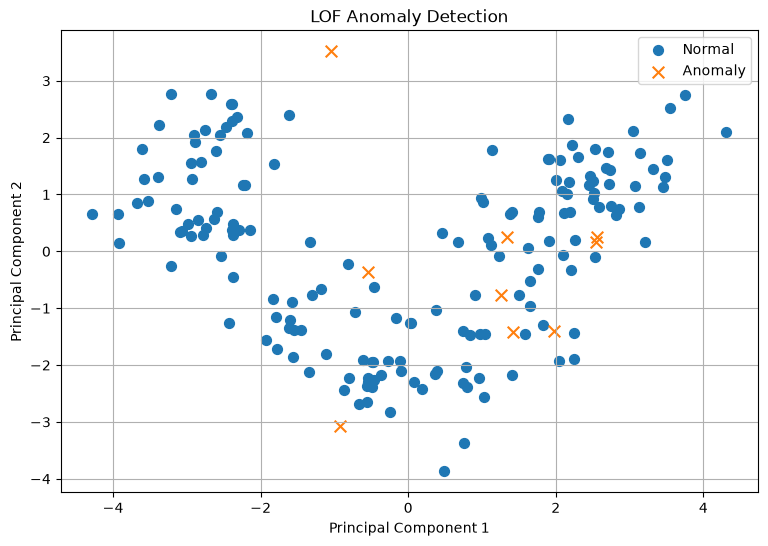

In [16]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[lof_predictions == 1, 0],
    X_pca[lof_predictions == 1, 1],
    label="Normal",
    s=50
)

plt.scatter(
    X_pca[lof_predictions == -1, 0],
    X_pca[lof_predictions == -1, 1],
    label="Anomaly",
    s=70,
    marker="x"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("LOF Anomaly Detection")

plt.legend()
plt.grid(True)

plt.show()